# 05 · Fresh holdout 2025 → latest — every pre-registered candidate

Following `outputs/research/preregistration.md`:
- The development period (2013–2022, notebook 04) produced **no eligible pick**: no candidate beat Buy & Hold's CAGR. All candidates are still reported here.
- Data after 2024-12-31 was **not downloaded until this notebook**. Models are refit yearly on all earlier data (2025 is predicted by models trained up to 2024, and 2026 by models trained up to 2025).
- Nothing in this notebook changes any definition or parameter.

Caveat (stated in the pre-registration): the researcher has general knowledge of 2025 market events, so this holdout is fresh *data* but not a perfectly blind *researcher*.

In [1]:
import sys, json, hashlib
from pathlib import Path
from datetime import date
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from src import config
from src.data import load_snapshot, audit
from src.research import research_dataset, build_candidates, evaluate, simulate_weights, metrics_from_values
from src.backtest import apply_rule, to_positions
from src.features import FEATURE_COLS

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
RES = config.OUTPUT_DIR / "research"
def savefig(name): plt.savefig(config.FIG_DIR / f"holdout_{name}.png", dpi=120, bbox_inches="tight")

# 1) the pre-registration is unchanged since it was hashed
prereg = (RES / "preregistration.md").read_bytes()
recorded = (RES / "preregistration.sha256").read_text().split()[0]
assert hashlib.sha256(prereg).hexdigest() == recorded, "pre-registration was modified!"
print("pre-registration hash verified:", recorded[:16], "…")

pre-registration hash verified: 06b9de8717aa4a65 …


## 1. Download the extended data (separate folder, so notebooks 01–04 keep using the original snapshot)

In [2]:
HOLD_DIR = config.ROOT / "data" / "holdout"; HOLD_DIR.mkdir(exist_ok=True)
existing = sorted(HOLD_DIR.glob("spy_*.csv"))
if existing:
    path = existing[-1]
else:
    import yfinance as yf
    df = yf.download("SPY", start=config.START, end=str(date.today()), auto_adjust=True, progress=False)
    df.columns = df.columns.get_level_values(0)
    df = df[["Open", "High", "Low", "Close", "Volume"]]; df.index.name = "Date"
    path = HOLD_DIR / f"spy_{date.today():%Y%m%d}.csv"; df.to_csv(path)
rawh = pd.read_csv(path, index_col="Date", parse_dates=True).sort_index()
print("snapshot:", path.name, "|", rawh.index.min().date(), "→", rawh.index.max().date())
display(pd.Series(audit(rawh)).to_frame("value").T)
# consistency with the original snapshot (adjusted levels differ by a factor, returns must agree)
orig = load_snapshot()
common = orig.index.intersection(rawh.index)
diff = (orig.loc[common, "Close"].pct_change() - rawh.loc[common, "Close"].pct_change()).abs().max()
print(f"max |daily return difference| vs original snapshot 2005–2024: {diff:.2e}")

snapshot: spy_20261013.csv | 2005-01-03 → 2026-10-12


,rows,first_date,last_date,missing_values,duplicate_dates,unsorted_index,high_below_open_close,low_above_open_close,non_positive_volume,gaps_over_4_calendar_days,abs_daily_return_over_7pct
value,5478,2005-01-03,2026-10-12,0,0,False,0,0,0,2,13


max |daily return difference| vs original snapshot 2005–2024: 1.36e-06


## 2. Walk-forward signals for 2025 and 2026 (pre-registered code path)

In [3]:
prices = rawh[["Open", "Close"]]
ds = research_dataset(rawh)
weights, diag = build_candidates(ds, years=[2025, 2026])
HOLD = (weights["S0 Buy & Hold"].index.min(), weights["S0 Buy & Hold"].index.max())
print("holdout:", HOLD[0].date(), "→", HOLD[1].date(), f"({len(weights['S0 Buy & Hold'])} trading days)")
rows, values = [], {}
for name, w in weights.items():
    m, v = evaluate(w, prices, name); rows.append(m); values[name] = v
hold = pd.DataFrame(rows).set_index("strategy")
hold["beats_BH_return"] = hold["total_return"] > hold.loc["S0 Buy & Hold", "total_return"]
hold[["total_return", "cagr", "ann_vol", "sharpe", "max_drawdown", "avg_exposure", "n_orders", "total_fees", "beats_BH_return"]]

holdout: 2025-01-02 → 2026-10-12 (445 trading days)


,total_return,cagr,ann_vol,sharpe,max_drawdown,avg_exposure,n_orders,total_fees,beats_BH_return
strategy,,,,,,,,,
S0 Buy & Hold,0.3484,0.1844,0.1691,1.0850,-0.1876,0.9980,1,99.9000,False
S1 Trend SMA200,0.2281,0.1234,0.1142,1.0760,-0.1122,0.8760,7,688.6400,False
S2 RF default-long,0.3209,0.1707,0.1612,1.0570,-0.1658,0.9330,17,1769.2500,False
S3 Drop-risk LR,0.1459,0.0802,0.1326,0.6480,-0.1621,0.9260,23,2399.5900,False
S4 Vol-target σ20,0.2478,0.1336,0.1376,0.9800,-0.1567,0.9330,19,420.2200,False
S5 Vol-target ML,0.2446,0.1319,0.1334,0.9960,-0.1675,0.9490,22,453.1400,False
S4L Vol-target σ20 ×1.5,0.2514,0.1354,0.1623,0.8640,-0.1773,1.1580,85,1529.7900,False
S5L Vol-target ML ×1.5,0.2163,0.1173,0.1550,0.7930,-0.1841,1.1770,154,2583.7600,False
S6L Trend + Vol-target ML ×1.5,0.2018,0.1097,0.1373,0.8270,-0.1245,1.0970,145,2869.4200,False


## 3. Reference (not pre-registered): the original frozen project model
`models/final_pipeline.joblib` (RF E06, trained 2010–2022, never refit) with its frozen signal rule (margin 0.05, min-hold 5, long-only). It is shown only to see how the original deliverable behaves on fresh data. It does not affect any conclusion about the candidates.

In [4]:
final = joblib.load(config.MODEL_DIR / "final_pipeline.joblib")
FROZEN = json.loads((config.OUTPUT_DIR / "frozen_config.json").read_text())
X = ds.loc[HOLD[0]:HOLD[1], FEATURE_COLS]
proba = pd.DataFrame(final.predict_proba(X), index=X.index, columns=final.classes_)
pos = to_positions(apply_rule(proba, FROZEN["signal_rule"]["margin"]), min_hold=FROZEN["signal_rule"]["min_hold"]).astype(float)
m, v = evaluate(pos, prices, "Original E06 model (frozen 2022)")
values[m["strategy"]] = v
ref = pd.DataFrame([m]).set_index("strategy")
ref[["total_return", "cagr", "sharpe", "max_drawdown", "avg_exposure", "n_orders", "total_fees"]]

,total_return,cagr,sharpe,max_drawdown,avg_exposure,n_orders,total_fees
strategy,,,,,,,
Original E06 model (frozen 2022),0.2404,0.1298,0.9610,-0.1290,0.5440,28,3096.2200


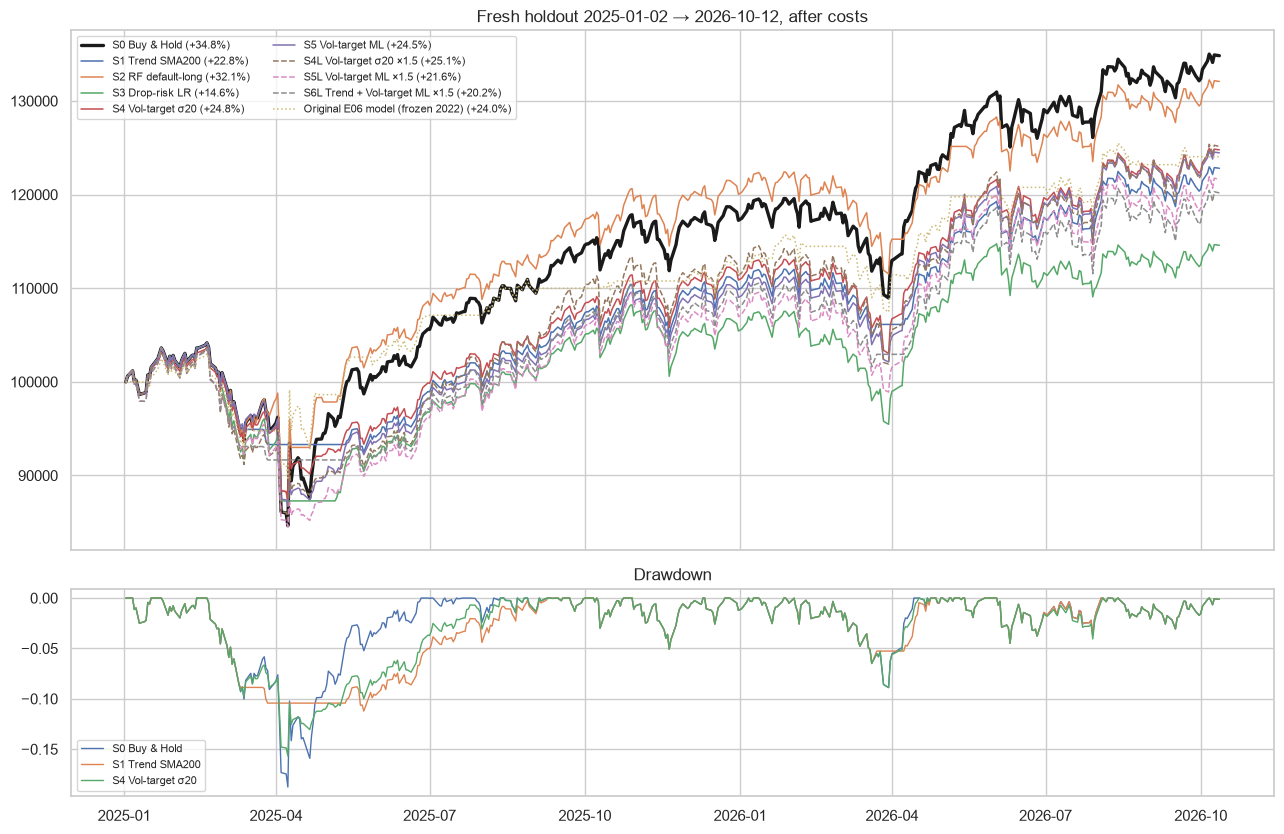

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
for name, v in values.items():
    tr = v.iloc[-1] / config.INIT_CASH - 1
    lw = 2.4 if name == "S0 Buy & Hold" else 1.1
    ls = "--" if "×1.5" in name else (":" if name.startswith("Original") else "-")
    ax[0].plot(v, label=f"{name} ({tr:+.1%})", lw=lw, ls=ls, color="k" if name == "S0 Buy & Hold" else None)
ax[0].legend(fontsize=8, ncol=2); ax[0].set_title(f"Fresh holdout {HOLD[0].date()} → {HOLD[1].date()}, after costs")
for name in ["S0 Buy & Hold", "S1 Trend SMA200", "S4 Vol-target σ20"]:
    v = values[name]; ax[1].plot(v / v.cummax() - 1, label=name, lw=1)
ax[1].set_title("Drawdown"); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig("equity"); plt.show()

**Reading — fresh holdout 2025-01-02 → 2026-10-12 (445 days, after costs).**
- **No candidate beats Buy & Hold (+34.8%, CAGR 18.4%, Sharpe 1.09).** The development conclusion holds on genuinely new data.
- The closest is **S2 RF default-long, +32.1%**. It was ahead of Buy & Hold for most of 2025: it avoided part of the April-2025 drop and re-entered quickly. It fell behind after exiting during the March-2026 dip and missing the rebound.
- **S1 trend filter**: +22.8% with Sharpe 1.08, about equal to Buy & Hold, and max drawdown **−11.2% vs −18.8%**. Again the gain is in risk, not return.
- The April-2025 crash repeats the 2020 lesson. The vol-target and trend strategies were cut back during or after the fall and missed much of the V-shaped recovery.
- The original project model (frozen in 2022, no refits) made +24.0% with only 54% average exposure.
- S4's Sharpe edge from the development period (0.89 vs 0.75) did **not** persist here (0.98 vs 1.09). Over two years even the risk-adjusted advantage is not reliable.

## 4. Post-hoc sensitivity (NOT pre-registered): borrowing cost of levered strategies
The pre-registration fixed a 5% borrowing rate. Here only that number varies; nothing is re-selected.

In [6]:
sens = []
for rate in [0.0, 0.02, 0.05]:
    for name in [n for n in weights if "×1.5" in n]:
        sim = simulate_weights(weights[name], prices, borrow_rate=rate)
        sens.append({"borrow_rate": rate, "strategy": name, "total_return": round(sim["value"].iloc[-1] / config.INIT_CASH - 1, 4)})
s = pd.DataFrame(sens).pivot(index="strategy", columns="borrow_rate", values="total_return")
s.loc["S0 Buy & Hold (reference)"] = hold.loc["S0 Buy & Hold", "total_return"]
s

borrow_rate,0.0000,0.0200,0.0500
strategy,,,
S4L Vol-target σ20 ×1.5,0.2761,0.2662,0.2514
S5L Vol-target ML ×1.5,0.2410,0.2311,0.2163
S6L Trend + Vol-target ML ×1.5,0.2263,0.2164,0.2018
S0 Buy & Hold (reference),0.3484,0.3484,0.3484


In [7]:
out = {"holdout_period": [str(HOLD[0].date()), str(HOLD[1].date())], "snapshot": path.name,
       "candidates": hold.reset_index().to_dict(orient="records"),
       "reference_original_model": ref.reset_index().to_dict(orient="records"),
       "borrow_sensitivity_posthoc": s.reset_index().to_dict(orient="records")}
(RES / "holdout_results.json").write_text(json.dumps(out, indent=2, default=str))
print("saved outputs/research/holdout_results.json")

saved outputs/research/holdout_results.json


**Reading (post-hoc).** Even with **free borrowing** the best levered strategy reaches +27.6%, still below Buy & Hold's +34.8%. The 5% borrowing assumption is not what decides the result. These strategies apply leverage only in calm periods and cap it at 1.5×, which is not enough to make up for the time spent de-risked around sell-offs and rebounds.